<a href="https://colab.research.google.com/github/thogaspar/Problem-Set-1-Econ_3916_PS1/blob/main/Problem_Set_1_Econ_3916_PS1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.
3. **AI is not allowed in Phases 1–3.** You write the dictionaries, the loops,
   the data fetches and the interpretation yourself. Phase 4 is where AI is
   required.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.

In this case: Two wage-earning individuals, at least one of which drives themselves to work. Standard majority of spending includes housing, food, and transportation.

> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [3]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.
household_basket = [
     {"Item": "Rent", "Price_2019": 1450, "Price_2024": 1750, "weight": 0.417},
     {"Item": "Food", "Price_2019": 550, "Price_2024": 840, "weight": 0.158},
     {"Item": "Transportation", "Price_2019": 850, "Price_2024": 1110, "weight": 0.245},
     {"Item": "Energy (EX-Gas)", "Price_2019": 120, "Price_2024": 150, "weight": 0.035},
     {"Item": "Medical", "Price_2019": 230, "Price_2024": 255, "weight": 0.066},
     {"Item": "Recreation", "Price_2019": 275, "Price_2024": 300, "weight": 0.079},
]

In [4]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

6 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

In [5]:
def laspeyres(basket, base_key, current_key):
    """Base-weighted price index for `basket`, with the base period = 100."""
    return sum(
        item["weight"]*(item[current_key]/item[base_key]) for item in basket
    )*100

def unweight_avg(basket, base_key, current_key):
    """Simple unweighted average change in price across categories, base period = 100."""
    temp =  [(item[current_key]/item[base_key]) for item in basket]
    return sum(temp)/len(temp)*100


unweighted = unweight_avg(household_basket, "Price_2019","Price_2024")
weighted = laspeyres(household_basket,"Price_2019","Price_2024" )
gap = abs(unweighted-weighted)

print(f"Unweighted Average index (2019 = 100): {unweighted:.2f} -> {unweighted-100:.2f}% Change")
print(f"Weighted Laspeyres index (2019 = 100): {weighted:.2f} -> {weighted-100:.2f}% Change")
print(f"Gap between Laspeyres & Unweighted indexes: {gap:.2f}%")

Unweighted Average index (2019 = 100): 124.83 -> 24.83% Change
Weighted Laspeyres index (2019 = 100): 126.76 -> 26.76% Change
Gap between Laspeyres & Unweighted indexes: 1.94%


In [6]:
# 1. the unweighted average price change across categories

# 2. your weighted Laspeyres index
# laspeyres(household_basket, "Price_2019", "Price_2024")

# 3. the gap between them

**Why do the two differ, and which would you defend to the client?**

*Your answer here.*

>The gap between our Laspeyres and Unweighted indexes arises from the differences in weighting. The unweighted index treats changes in prices across categories as having an equal impact (a 1% increase in rent is equal in effect to a 1% increase in recreation). Our Laspeyres index reweights categories according to their share of typical household spending patterns (a 1% increase in rent impacts the standard household more than a 1% increase in recreation). Due to its more refined and applicable weighting, I would defend the Laspeyres index over the unweighted.



---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [7]:
series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02", "CPIMEDSL", "CUUR0000SAH2", "CPIRECSL"]
def load_fred(series_id, start="1947-01-01", end=None):
    """Return one FRED series as a pandas Series indexed by date.
    """
    url = (f"https://fred.stlouisfed.org/graph/fredgraph.csv?"
           f"id={series_id}&cosd={start}")
    if end is not None:
        url += f"&coed={end}"
    frame = pd.read_csv(url)
    frame.columns = ["date", series_id]
    frame["date"] = pd.to_datetime(frame["date"])
    frame[series_id] = pd.to_numeric(frame[series_id], errors="coerce")
    return frame.set_index("date")[series_id].dropna()

cpi = load_fred("CPIAUCSL")
rent = load_fred("CUSR0000SEHA")
food = load_fred("CUSR0000SAF11")
used_cars = load_fred("CUSR0000SETA02")
medical = load_fred("CPIMEDSL")
utility = load_fred("CUUR0000SAH2")
rec = load_fred("CPIRECSL")

| Series | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|
| `CPIAUCSL` |The benchmark consumer price index for all Urban Consumers. Useful to compare to our findings. | It's a national average, subsets of consumer data or specific populations may/may not allign with this average.
| `CUSR0000SEHA` |It tracks average consumer rent of their primary residence, a close match to our rent item. | Fails to capture owners of homes (mortgages), ideally would tailor this figure to the geography of the consumer for most accurate results. |
| `CUSR0000SAF11` | Tracks average cost of food at home across the U.S., suitable for food/grocery spending habits for the average working age consumer. | Fails to capture food outside of the home including restaurants and takeout.|
| `CUSR0000SETA02` |An average for the cost of a used car/truck, our "standard household", included one consumer who drives to work. |Fails to capture alternative transporation methods, upkeep/insurance/maintainence of car, as well as new car sales. |
| `CPIMEDSL` | Tracks average out of pocket expenses (post-insurance) for medical care in the U.S., suitable for our medical item. | Fails to capture differences between medical plans (ex: deductible), and fails to differentiate between insured/uninsured.|
| `CUUR0000SAH2` |Covers household energy/gas, in addition to water, sewer, and trash expenditures, suitable for our utilities item. |Fails to capture utilities that may be included in the price of rent, and doesn't include all utilities such as internet/phone. |
| `CPIRECSL` | Tracks hobby-based/recreational spending of US urban consumers, suitable for our "rec" item| The recreation item is likely subject to a higher degree of substitution than other items like rent or utilities.  |

### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

In [8]:
# Rebase to 2019 = 100
def rebase (series, year="2019"):
  return series/series.loc[year].mean()*100

cpi_rb = rebase(cpi)
rent_rb = rebase(rent)
food_rb = rebase(food)
used_cars_rb = rebase(used_cars)
medical_rb = rebase(medical)
utility_rb = rebase(utility)
rec_rb = rebase(rec)

for name, s in [("cpi", cpi_rb), ("rent", rent_rb), ("food", food_rb),
                ("used_cars", used_cars_rb), ("medical", medical_rb),
                ("utility", utility_rb), ("rec", rec_rb)]:
    print(name, round(s.loc["2019"].mean(), 2))

cpi 100.0
rent 100.0
food 100.0
used_cars 100.0
medical 100.0
utility 100.0
rec 100.0


<function matplotlib.pyplot.show(close=None, block=None)>

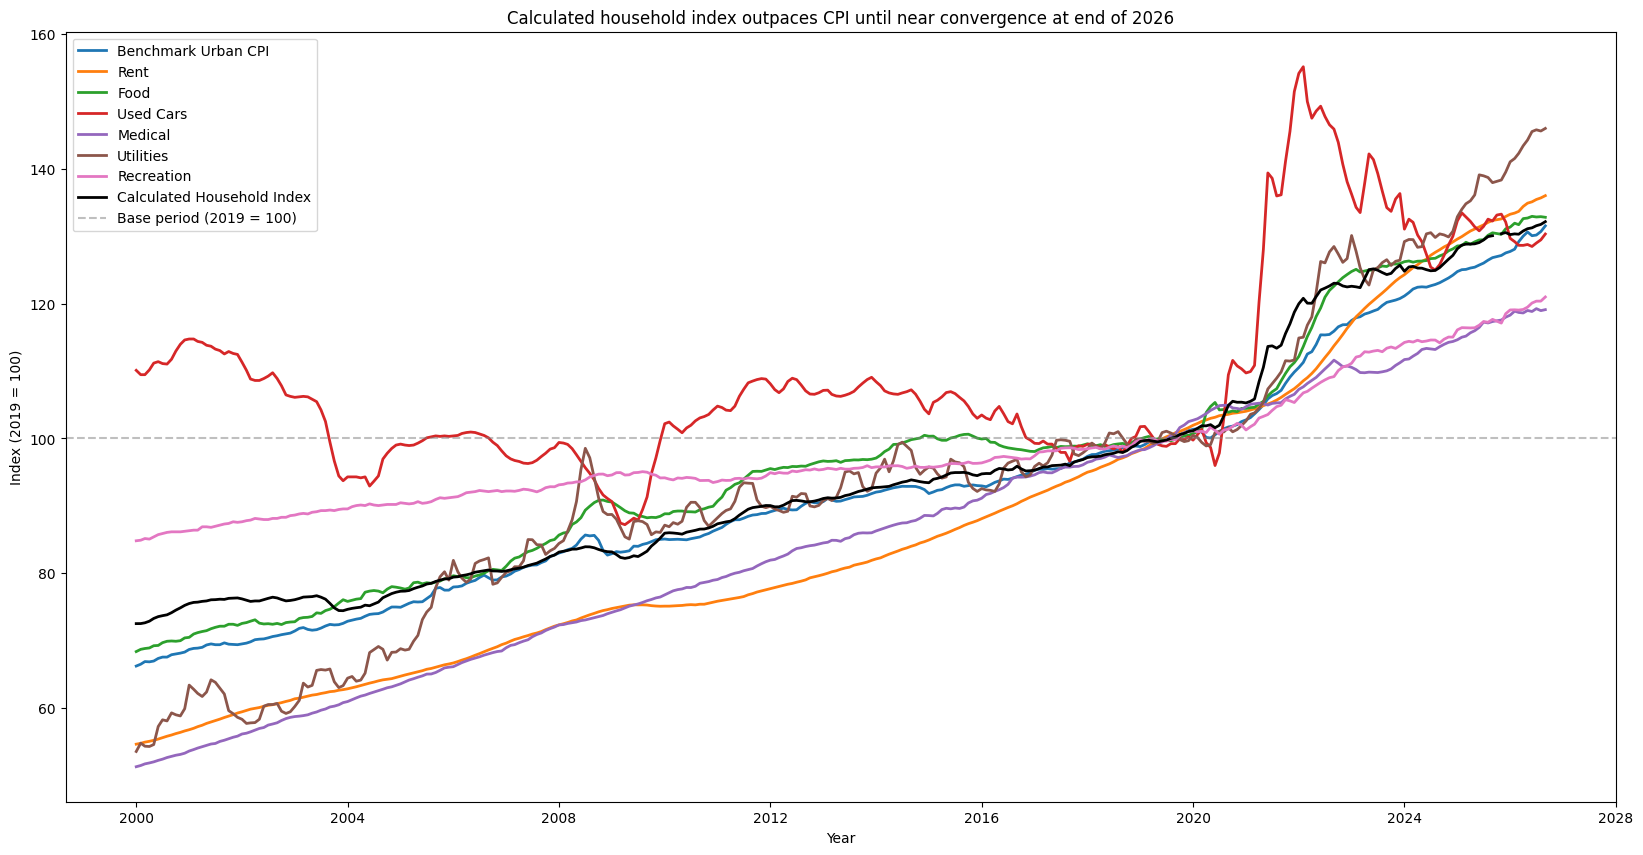

In [9]:
# One chart: every rebased series, plus your household index
household_rb = (rent_rb*0.417+
                food_rb*0.158+
                used_cars_rb*0.245+
                medical_rb*0.066+
                utility_rb*0.035+
                rec_rb*0.079)

fig, ax = plt.subplots(figsize=(20, 10))

for n, labels in [(cpi_rb,"Benchmark Urban CPI"),
                (rent_rb, "Rent"),
                (food_rb, "Food"),
                (used_cars_rb, "Used Cars"),
                (medical_rb, "Medical"),
                (utility_rb, "Utilities"),
                (rec_rb, "Recreation")
                  ]:
  n = n.loc["2000":]
  ax.plot (n.index, n, linewidth=2, label=labels)

h=household_rb.loc["2000":]
ax.plot (h.index, h, color = "Black", linewidth=2, label="Calculated Household Index")
ax.axhline(y=100, color="gray", linestyle="--", alpha=0.5,
              label="Base period (2019 = 100)")
ax.set_xlabel("Year")
ax.set_ylabel("Index (2019 = 100)")
ax.set_title("Calculated household index outpaces CPI until near convergence at end of 2026")
ax.legend(frameon=True)
plt.show


---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet — a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. Report the count whatever it
> is; if it is not zero, list the missing months.

In [10]:
# First observation, last observation, frequency and missing months, for every series
for names, s in [("CPI", cpi),
                ("Rent", rent),
                ("Food", food ),
                ( "Used Cars", used_cars),
                ("Medical", medical),
                ("Utilities", utility),
                ("Recreation", rec )
                  ]:
  t=s.asfreq("MS")
  print(names, s.index[0], s.index[-1], s.asfreq("MS").isna().sum(), t[t.isna()].index )


CPI 1947-01-01 00:00:00 2026-09-01 00:00:00 1 DatetimeIndex(['2025-10-01'], dtype='datetime64[ns]', name='date', freq='MS')
Rent 1981-01-01 00:00:00 2026-09-01 00:00:00 1 DatetimeIndex(['2025-10-01'], dtype='datetime64[ns]', name='date', freq='MS')
Food 1952-01-01 00:00:00 2026-09-01 00:00:00 1 DatetimeIndex(['2025-10-01'], dtype='datetime64[ns]', name='date', freq='MS')
Used Cars 1953-01-01 00:00:00 2026-09-01 00:00:00 0 DatetimeIndex([], dtype='datetime64[ns]', name='date', freq='MS')
Medical 1947-01-01 00:00:00 2026-09-01 00:00:00 1 DatetimeIndex(['2025-10-01'], dtype='datetime64[ns]', name='date', freq='MS')
Utilities 1952-12-01 00:00:00 2026-09-01 00:00:00 1 DatetimeIndex(['2025-10-01'], dtype='datetime64[ns]', name='date', freq='MS')
Recreation 1993-01-01 00:00:00 2026-09-01 00:00:00 1 DatetimeIndex(['2025-10-01'], dtype='datetime64[ns]', name='date', freq='MS')


| Series | First | Last | Frequency | Missing months |
|---|---|---|---|---|
|CPI |1947-01-01 | 2026-09-01| 1| 2025-10-01|
|Rent |1981-01-01 |2026-09-01 | 1| 2025-10-01|
|Food |1952-01-01 |2026-09-01 | 1| 2025-10-01|
|User Cars | 1953-01-01|2026-09-01 | 0|N/A |
|Medical |1947-01-01 |2026-09-01 |1 | 2025-10-01|
|Utilities |1952-12-01 |2026-09-01 |1 |2025-10-01 |
|Recreation |1993-01-01 |2026-09-01 |1 | 2025-10-01|

### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [25]:
# Start dates side by side, and the common sample
sample = [cpi, rent, food, used_cars, medical, utility, rec]
common_start = max(t.index[0] for t in sample)
common_len = min(len(t) for t in sample)
long_disc = max(len(t) for t in sample)-common_len

print("Common Sample starts:", common_start)
print("Common Sample length:", common_len, "Months")
print("Longest series discards:", long_disc, "Months")




Common Sample starts: 1993-01-01 00:00:00
Common Sample length: 404 Months
Longest series discards: 552 Months


In [ ]:
# Headline comparison: full history vs common sample;
# Struggling to figure out what is meant by a headline comparison, and am skipping this step

**What restricting to the common sample assumes, and what not restricting assumes:**

*Your answer here.*

### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

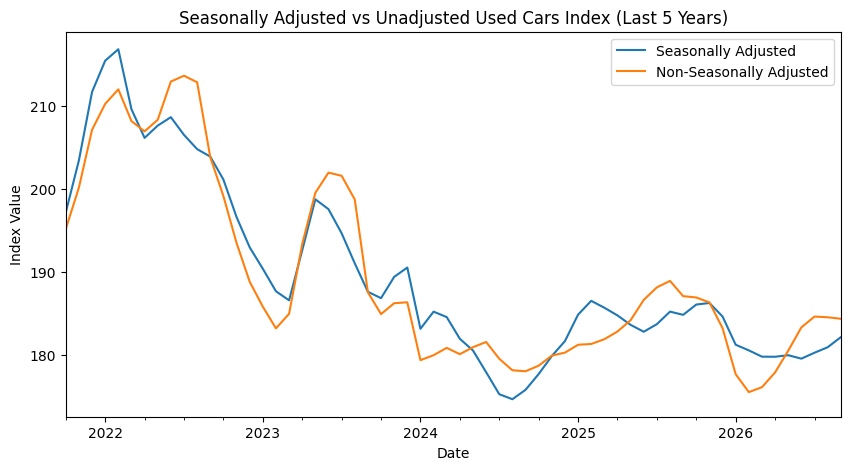

In [30]:
# Seasonally adjusted vs unadjusted, last five years
twin_used_cars = load_fred("CUUR0000SETA02")

comparison_adj = used_cars.iloc[-60:]
comparison_unadj = twin_used_cars.iloc[-60:]

plt.figure(figsize=(10, 5))
comparison_adj.plot(label="Seasonally Adjusted")
comparison_unadj.plot(label="Non-Seasonally Adjusted")
plt.title("Seasonally Adjusted vs Unadjusted Used Cars Index (Last 5 Years)")
plt.xlabel("Date")
plt.ylabel("Index Value")
plt.legend()
plt.show()

**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

The gap between the two lines represents the "seasonal noise" found in the index data. BLS realizes some fluctuations in economic activity are due to seasonal reasons, ex: weather, holidays, school schedules. It is visible in the oscilation of our non-seasonal line as each year it crosses both above and below the adjusted line. In this brief we should use the seasonally adjusted index, as we are interested in the true underlying price movement as opposed to seasonal effects.

---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required.

### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

Base-case Laspeyres index (2019 = 100): 126.76

                 base_weight  price_relative  swing_pts  pts_per_0.01_weight
Item                                                                        
Food                   0.158           1.527     15.418                0.308
Recreation             0.079           1.091      9.594               -0.192
Medical                0.066           1.109      8.508               -0.170
Rent                   0.417           1.207      5.209               -0.104
Transportation         0.245           1.306      2.533                0.051
Energy (EX-Gas)        0.035           1.250      0.914               -0.018


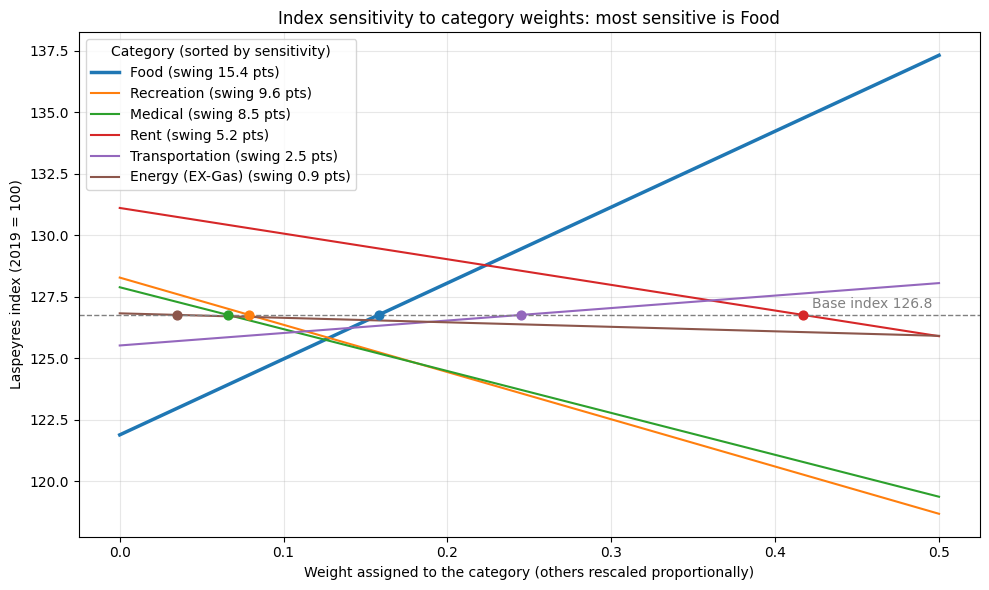

In [31]:
# Paste the AI's code here, run it, and correct it where it is wrong

# ---------------------------------------------------------------
# 1. Build the base-case index from household_basket
# ---------------------------------------------------------------
df = pd.DataFrame(household_basket)
df["relative"] = df["Price_2024"] / df["Price_2019"]   # price relative P24/P19

relative = df["relative"].to_numpy(dtype=float)
w0 = df["weight"].to_numpy(dtype=float)

# Laspeyres weights are base-period expenditure shares, so they must sum to 1.
# If yours sum to 100 or 0.99, this puts them on the same footing.
w0 = w0 / w0.sum()

base_index = 100 * np.sum(w0 * relative)
print(f"Base-case Laspeyres index (2019 = 100): {base_index:.2f}\n")

# ---------------------------------------------------------------
# 2. Re-weighting function
# ---------------------------------------------------------------
def reweighted_index(k, w_k):
    """Index when category k's weight is set to w_k and every other
    category is scaled by the same factor so the weights still sum to 1."""
    # MECHANISM CHECK 1: why renormalise?
    # A Laspeyres index is a weighted *average* of price relatives, so the
    # weights must sum to 1. If we changed one weight and left the rest alone,
    # the weights would sum to something other than 1 and the index would
    # change for the wrong reason: a level effect (the basket gets bigger or
    # smaller) mixed in with the composition effect we want to measure.
    # Scaling the others by the same factor (1 - w_k) / (1 - w0[k]) keeps
    # their relative proportions intact. That isolates the question
    # "what if this category mattered more or less?" and holds the mix of
    # the other five fixed.
    new_w = w0 * (1 - w_k) / (1 - w0[k])
    new_w[k] = w_k
    return 100 * np.sum(new_w * relative)

# ---------------------------------------------------------------
# 3. Sweep each category's weight from 0 to 0.5
# ---------------------------------------------------------------
sweep = np.linspace(0, 0.5, 101)

results = pd.DataFrame(
    {item: [reweighted_index(k, w) for w in sweep]
     for k, item in enumerate(df["Item"])},
    index=sweep,
)

# Sensitivity = swing in the index across the identical 0 to 0.5 sweep,
# so the categories are directly comparable.
sensitivity = pd.DataFrame({
    "base_weight": w0,
    "price_relative": relative,
    "swing_pts": (results.max() - results.min()).to_numpy(),
    "pts_per_0.01_weight": ((results.iloc[-1] - results.iloc[0]) / 0.5 * 0.01).to_numpy(),
}, index=df["Item"]).sort_values("swing_pts", ascending=False)

print(sensitivity.round(3))
most_sensitive = sensitivity.index[0]

# ---------------------------------------------------------------
# 4. One chart
# ---------------------------------------------------------------
# MECHANISM CHECK 2: what does high sensitivity to one category mean?
# Each line is exactly linear: index = w * r_k + (1 - w) * R_others, where
# R_others is the weighted-average price relative of the other categories.
# The slope is therefore r_k - R_others: how far the category's inflation sits
# from everyone else's. A steep line means (a) the headline number is
# effectively a statement about that one category, (b) any error in its weight
# (survey noise, a household whose spending differs from the average basket)
# passes almost one-for-one into the index, and (c) the index can differ a lot
# between households with different spending shares. In that case report the
# index with a range or a category-contribution breakdown, not a single point.

fig, ax = plt.subplots(figsize=(10, 6))

for item in sensitivity.index:                       # steepest first in legend
    k = df.index[df["Item"] == item][0]
    swing = sensitivity.loc[item, "swing_pts"]
    line, = ax.plot(sweep, results[item], linewidth=2.5 if item == most_sensitive else 1.5,
                    label=f"{item} (swing {swing:.1f} pts)")
    # Mark where each category currently sits
    ax.scatter(w0[k], base_index, color=line.get_color(), zorder=3, s=40)

ax.axhline(base_index, color="grey", linestyle="--", linewidth=1)
ax.annotate(f"Base index {base_index:.1f}", xy=(0.5, base_index),
            xytext=(-5, 5), textcoords="offset points", ha="right", color="grey")

ax.set_xlabel("Weight assigned to the category (others rescaled proportionally)")
ax.set_ylabel("Laspeyres index (2019 = 100)")
ax.set_title(f"Index sensitivity to category weights: most sensitive is {most_sensitive}")
ax.grid(True, alpha=0.3)
ax.legend(title="Category (sorted by sensitivity)", loc="best")
fig.tight_layout()
fig.savefig("weight_sensitivity.png", dpi=200)
plt.show()

**What did the model get wrong, or get right in a way you had to check? Show the check.**

I cannot find anything directly "wrong" with the models output, apart from unnecessary importing that was removed. Relative price is a quick calculation and thus checked by hand: (Ex Rent: (1750-1450)/1750 = 0.207.

To further test a full datapoint and its output, I also calculated Food's  weight=0.5 and the index output by hand, setting food's new weight to 0.5. 0.5/0.842=0.589, or the new multiplier to reweight the rest of the basket.

(0.589)0.079+(0.589)0.066+(0.589)0.417+(0.589)0.245+(0.589)0.035 ~0.496 (likely different due to rounding)

Then new weights * relative prices

0.5(1.527)

(0.589)0.079(1.091)

(0.589)0.066(1.109)

(0.589)0.417(1.207)

(0.589)0.245(1.306)

(0.589)0.035(1.25)

= 1.367 (some difference due to rounding likely), but this does visually match our food datapoint @ weight =0.5, as it sits just under 137.5.




### AI Transcript

**Model: Claude (Sonnet 5.5)** &nbsp; **Date: 10/19/26**

*Paste the prompt exactly as you sent it, then the model's reply exactly as it
came back, before your corrections.*

*Pasted Prompt*:

[Prep] Act as an applied economist who builds reproducible analysis for client deliverables.
[Request] I have a household price index built as a weighted Laspeyres over six spending categories, in a list of dicts named household_basket with keys Item, Price_2019, Price_2024 and weight. Write Python that sweeps each category’s weight from 0 to 0.5, holding the others in proportion, recomputes the index, and produces a single chart showing which category’s weight the result is most sensitive to.
[Iterate] numpy, pandas and matplotlib only. Reuse my variable names. No deprecated matplotlib arguments.
[Mechanism Check] Add comments explaining why renormalising the other weights is necessary, and what it would mean if the index were highly sensitive to a single category.
[Evaluate] Tell me which category dominates my result and what I should say to a client about it.

*Exact Reply*

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# 1. Build the base-case index from household_basket
# ---------------------------------------------------------------
df = pd.DataFrame(household_basket)
df["relative"] = df["Price_2024"] / df["Price_2019"]   # price relative P24/P19

relative = df["relative"].to_numpy(dtype=float)
w0 = df["weight"].to_numpy(dtype=float)

# Laspeyres weights are base-period expenditure shares, so they must sum to 1.
# If yours sum to 100 or 0.99, this puts them on the same footing.
w0 = w0 / w0.sum()

base_index = 100 * np.sum(w0 * relative)
print(f"Base-case Laspeyres index (2019 = 100): {base_index:.2f}\n")

# ---------------------------------------------------------------
# 2. Re-weighting function
# ---------------------------------------------------------------
def reweighted_index(k, w_k):
    """Index when category k's weight is set to w_k and every other
    category is scaled by the same factor so the weights still sum to 1."""
    # MECHANISM CHECK 1: why renormalise?
    # A Laspeyres index is a weighted *average* of price relatives, so the
    # weights must sum to 1. If we changed one weight and left the rest alone,
    # the weights would sum to something other than 1 and the index would
    # change for the wrong reason: a level effect (the basket gets bigger or
    # smaller) mixed in with the composition effect we want to measure.
    # Scaling the others by the same factor (1 - w_k) / (1 - w0[k]) keeps
    # their relative proportions intact. That isolates the question
    # "what if this category mattered more or less?" and holds the mix of
    # the other five fixed.
    new_w = w0 * (1 - w_k) / (1 - w0[k])
    new_w[k] = w_k
    return 100 * np.sum(new_w * relative)

# ---------------------------------------------------------------
# 3. Sweep each category's weight from 0 to 0.5
# ---------------------------------------------------------------
sweep = np.linspace(0, 0.5, 101)

results = pd.DataFrame(
    {item: [reweighted_index(k, w) for w in sweep]
     for k, item in enumerate(df["Item"])},
    index=sweep,
)

# Sensitivity = swing in the index across the identical 0 to 0.5 sweep,
# so the categories are directly comparable.
sensitivity = pd.DataFrame({
    "base_weight": w0,
    "price_relative": relative,
    "swing_pts": (results.max() - results.min()).to_numpy(),
    "pts_per_0.01_weight": ((results.iloc[-1] - results.iloc[0]) / 0.5 * 0.01).to_numpy(),
}, index=df["Item"]).sort_values("swing_pts", ascending=False)

print(sensitivity.round(3))
most_sensitive = sensitivity.index[0]

# ---------------------------------------------------------------
# 4. One chart
# ---------------------------------------------------------------
# MECHANISM CHECK 2: what does high sensitivity to one category mean?
# Each line is exactly linear: index = w * r_k + (1 - w) * R_others, where
# R_others is the weighted-average price relative of the other categories.
# The slope is therefore r_k - R_others: how far the category's inflation sits
# from everyone else's. A steep line means (a) the headline number is
# effectively a statement about that one category, (b) any error in its weight
# (survey noise, a household whose spending differs from the average basket)
# passes almost one-for-one into the index, and (c) the index can differ a lot
# between households with different spending shares. In that case report the
# index with a range or a category-contribution breakdown, not a single point.

fig, ax = plt.subplots(figsize=(10, 6))

for item in sensitivity.index:                       # steepest first in legend
    k = df.index[df["Item"] == item][0]
    swing = sensitivity.loc[item, "swing_pts"]
    line, = ax.plot(sweep, results[item], linewidth=2.5 if item == most_sensitive else 1.5,
                    label=f"{item} (swing {swing:.1f} pts)")
    # Mark where each category currently sits
    ax.scatter(w0[k], base_index, color=line.get_color(), zorder=3, s=40)

ax.axhline(base_index, color="grey", linestyle="--", linewidth=1)
ax.annotate(f"Base index {base_index:.1f}", xy=(0.5, base_index),
            xytext=(-5, 5), textcoords="offset points", ha="right", color="grey")

ax.set_xlabel("Weight assigned to the category (others rescaled proportionally)")
ax.set_ylabel("Laspeyres index (2019 = 100)")
ax.set_title(f"Index sensitivity to category weights: most sensitive is {most_sensitive}")
ax.grid(True, alpha=0.3)
ax.legend(title="Category (sorted by sensitivity)", loc="best")
fig.tight_layout()
fig.savefig("weight_sensitivity.png", dpi=200)
plt.show()

### Task 4.2: The written finding (10 pts)

250 words at most, to the director. A number in the first sentence, no code,
and a confidence level.

Household prices have risen by 26.8% over the time 2019>2024 (indexed to 126.8 with base year 2019=100). Within this index, the subcategory most sensitive to changes in weight was food, which itself rose 52.7% over the same period, and for each additional 1% in basket share, it causes the index to rise by 0.31 points. Although rent is the largest weight within our index (0.417), its sensitivty to weight changes only ranks 4th, and it's price increase was a more moderate 20.7%. I maintain moderate levels of confident in the results, as a key datapoints from the sensitivty analysis were checked by hand. However, it should be noted that holding our 2019 basket fixed (same goods pruchased), liekly overstate the effects, as consumers are likely to substitute if prices rise too fast.

---
### Before you submit
- [ ] Every step above has output, and every explanation is in a text cell
- [ ] The AI Transcript names the model and the date
- [ ] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1/` on GitHub